<div style="background:#0B1F4B;padding:22px 26px;border-radius:12px;border:3px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/26UAMPC204-Artificial-Intelligence/main/assets/logo.png" alt="Sanjivani University" width="92" style="float:right;background:#FFFFFF;border:2px solid #C9A227;border-radius:8px;padding:3px;margin-left:14px">
<div style="color:#C9A227;font-size:14px;letter-spacing:2px;font-weight:bold">26UAMPC204 · ARTIFICIAL INTELLIGENCE LAB · SANJIVANI UNIVERSITY</div>
<div style="color:#FFFFFF;font-size:30px;font-weight:bold;margin-top:6px">Experiment 3: Hill Climbing and Greedy Best-First Search</div>
<div style="color:#F6EBC8;font-size:15px;margin-top:8px"><b>Course Outcome:</b> CO204.2 &nbsp;|&nbsp; <b>Faculty:</b> Dr. S. Satyanarayana, Professor &amp; Advisor, AI &amp; DS</div>
<div style="clear:both"></div></div>

<div style="background:#F6EBC8;padding:12px 18px;border-radius:8px;margin-top:10px;font-family:'Times New Roman',serif;color:#0B1F4B">
<b>🎯 Aim:</b> Implement steepest-ascent hill climbing (with random restarts) for the 8-queens problem and Greedy Best-First Search for a route problem; study local maxima and success rates.</div>

## 📘 Theory

**Hill climbing** keeps one current state and moves to the best neighbour while it improves the objective. It can get stuck at **local maxima**, **plateaux** and **ridges**; **random restarts** make it complete with probability approaching 1.
**Greedy Best-First Search** expands the node with the lowest $h(n)$ — fast, but not optimal.
For 8-queens, the objective counts attacking pairs $h$ (goal $h=0$).

## 🧭 Algorithm

1. Start from a random complete state.
2. Evaluate all neighbours (move one queen within its column).
3. If the best neighbour is not better than the current state, stop (local optimum).
4. Otherwise move to it and repeat; on failure, restart from a new random state.

## ⚙️ Setup

In [1]:
# ---- Course style (navy & gold, Times) -------------------------------------
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

NAVY, NAVY2, GOLD, GOLDL = "#0B1F4B", "#1F3A7A", "#C9A227", "#F6EBC8"
TEAL, CRIMSON, LEAF, MIST, SLATE = "#0E7C86", "#A4243B", "#2E7D32", "#EEF2F8", "#4A5568"
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.edgecolor": SLATE, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlesize": 14, "axes.labelcolor": NAVY, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
FIG = os.path.join("..", "assets", "figures");    os.makedirs(FIG, exist_ok=True)
ANI = os.path.join("..", "assets", "animations"); os.makedirs(ANI, exist_ok=True)

def save_gif(anim, name, fps=2):
    path = os.path.join(ANI, name)
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close("all")
    return path
print("Environment ready  ✓  numpy", np.__version__, "| matplotlib", matplotlib.__version__)


Environment ready  ✓  numpy 2.5.3 | matplotlib 3.11.2


## 💻 Implementation and Output

In [2]:
rng = np.random.default_rng(42)
def attacks(s):
    n = len(s); return sum(1 for i in range(n) for j in range(i + 1, n) if s[i] == s[j] or abs(s[i] - s[j]) == j - i)
def hill_climb(n=8, max_steps=100):
    s = list(rng.integers(0, n, n)); trace = [s[:]]
    for _ in range(max_steps):
        cur = attacks(s); best, best_s = cur, None
        for col in range(n):
            for row in range(n):
                if row != s[col]:
                    t = s[:]; t[col] = row; v = attacks(t)
                    if v < best: best, best_s = v, t
        if best_s is None: break
        s = best_s; trace.append(s[:])
    return s, attacks(s), trace

wins, steps = 0, []
for trial in range(500):
    s, h, tr = hill_climb()
    wins += (h == 0); steps.append(len(tr) - 1)
print(f"Steepest-ascent success rate on 8-queens: {wins/500:.1%} (textbook ≈ 14%)   mean steps = {np.mean(steps):.1f}")

Steepest-ascent success rate on 8-queens: 15.4% (textbook ≈ 14%)   mean steps = 3.2


Solution: [6, 0, 2, 7, 5, 3, 1, 4] found after 1 random restarts;  attacking pairs = 0


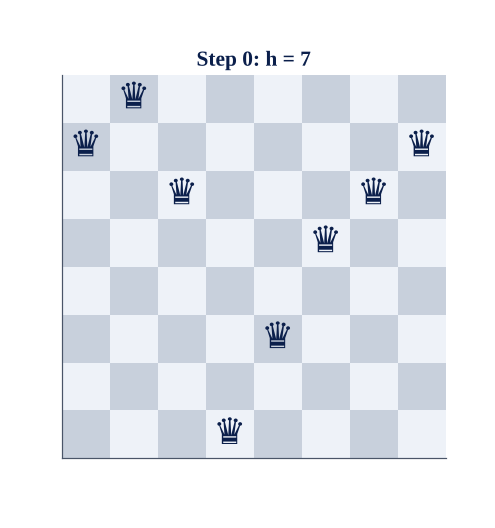

In [3]:
def restart_hc(n=8):
    restarts = 0
    while True:
        s, h, tr = hill_climb(n)
        if h == 0: return s, restarts, tr
        restarts += 1
sol, r, trace = restart_hc()
sol = [int(v) for v in sol]; trace = [[int(v) for v in t] for t in trace]
print("Solution:", sol, "found after", r, "random restarts;  attacking pairs =", attacks(sol))

def board(ax, s, title):
    n = len(s)
    ax.imshow([[(i + j) % 2 for j in range(n)] for i in range(n)], cmap=matplotlib.colors.ListedColormap([MIST, "#C8D0DC"]))
    for c, r in enumerate(s): ax.text(c, r, "♛", ha="center", va="center", fontsize=24, fontfamily="DejaVu Sans", color=NAVY if attacks(s) else LEAF)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
fig, ax = plt.subplots(figsize=(4.5, 4.8))
gif = save_gif(animation.FuncAnimation(fig, lambda k: (ax.clear(), board(ax, trace[min(k, len(trace)-1)], f"Step {min(k, len(trace)-1)}: h = {attacks(trace[min(k, len(trace)-1)])}")),
                frames=len(trace) + 3), "exp03_hill_climbing_queens.gif", fps=1.5)
display(Image(filename=gif))

In [4]:
hs = [attacks(t) for t in trace]
plt.figure(figsize=(6, 3.2)); plt.plot(hs, "-o", color=NAVY, mfc=GOLD, ms=8)
plt.xlabel("step"); plt.ylabel("attacking pairs h"); plt.title("Hill climbing descends h to 0 (successful run)")
plt.tight_layout(); plt.savefig(f"{FIG}/exp03_hc_curve.png", dpi=130); plt.show()

### Greedy Best-First Search on the Romania map (straight-line-distance heuristic)

In [5]:
roads = {("Arad","Zerind"):75,("Arad","Sibiu"):140,("Arad","Timisoara"):118,("Zerind","Oradea"):71,("Oradea","Sibiu"):151,
 ("Timisoara","Lugoj"):111,("Lugoj","Mehadia"):70,("Mehadia","Drobeta"):75,("Drobeta","Craiova"):120,("Craiova","Rimnicu"):146,
 ("Craiova","Pitesti"):138,("Sibiu","Fagaras"):99,("Sibiu","Rimnicu"):80,("Rimnicu","Pitesti"):97,("Fagaras","Bucharest"):211,
 ("Pitesti","Bucharest"):101,("Bucharest","Giurgiu"):90,("Bucharest","Urziceni"):85}
G = {}
for (a, b), d in roads.items(): G.setdefault(a, {})[b] = d; G.setdefault(b, {})[a] = d
SLD = {"Arad":366,"Bucharest":0,"Craiova":160,"Drobeta":242,"Fagaras":176,"Giurgiu":77,"Lugoj":244,"Mehadia":241,
       "Oradea":380,"Pitesti":100,"Rimnicu":193,"Sibiu":253,"Timisoara":329,"Urziceni":80,"Zerind":374}
def best_first(start, goal, f):
    import heapq
    fr = [(f(start, 0), start, 0, [start])]; seen = set(); order = []
    while fr:
        _, n, g, path = heapq.heappop(fr)
        if n in seen: continue
        seen.add(n); order.append(n)
        if n == goal: return path, g, order
        for m, d in G[n].items(): heapq.heappush(fr, (f(m, g + d), m, g + d, path + [m]))
gp, gc, go = best_first("Arad", "Bucharest", lambda n, g: SLD[n])
ap, ac, ao = best_first("Arad", "Bucharest", lambda n, g: g + SLD[n])
print("Greedy best-first:", " → ".join(gp), f"= {gc} km   (expanded {len(go)})")
print("A*               :", " → ".join(ap), f"= {ac} km   (expanded {len(ao)})")

Greedy best-first: Arad → Sibiu → Fagaras → Bucharest = 450 km   (expanded 4)
A*               : Arad → Sibiu → Rimnicu → Pitesti → Bucharest = 418 km   (expanded 6)


## ✅ Result and Conclusion

<div style="border-left:6px solid #2E7D32;background:#E3F2E4;padding:12px 18px;border-radius:6px;font-family:'Times New Roman',serif;color:#1A202C">
<b style="color:#2E7D32">Conclusion</b><br>Plain steepest-ascent hill climbing solves only about one in seven 8-queens instances because it halts at local minima of h; random restarts always reach a solution. Greedy best-first reaches Bucharest quickly (450 km) but A* finds the optimal 418 km route.</div>

## 🎤 Viva Questions

1. Why does hill climbing get stuck? Name three landscape features responsible.
2. How does random-restart hill climbing achieve completeness?
3. Why is greedy best-first search not optimal? Give the Romania counter-example.
4. What is the difference between hill climbing and simulated annealing?
5. What objective function did you use for 8-queens, and what is its maximum value?